# Palmer Penguins: unsupervised learning
Author: Marcos Robinat. PRDL and MLLB, 2026-2027.

## 1. Question and scope
Can physical measurements describe groups without providing species labels during fitting? We use the same development allocation, four physical inputs and complete-case rule as notebooks 01 and 02. The final test is not used. A cluster number is a name, not a species prediction. Run from a fresh CPU kernel with the original penguins.csv beside this notebook (or upload when prompted).

Species was used for the inherited stratified development/test allocation. It is never supplied to the fitted unsupervised transformations or used to choose their settings.

In [1]:
from pathlib import Path
import hashlib
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.model_selection import train_test_split
print('Python:', platform.python_version(), '| scikit-learn:', sklearn.__version__)

Python: 3.12.14 | scikit-learn: 1.9.1


In [2]:
DATA_PATH = Path('penguins.csv')
EXPECTED_SHA256 = 'f204db2c753b0937caac3cb35258562c14f073e4bbc76be24b4c51ce22767a93'
if not DATA_PATH.exists():
    try:
        from google.colab import files
    except ImportError as error:
        raise FileNotFoundError('Place the original penguins.csv beside this notebook.') from error
    print('Upload the unchanged penguins.csv from the Penguins_ML folder.')
    files.upload()
source_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
if source_hash != EXPECTED_SHA256:
    raise ValueError('The CSV differs from the recorded source. Check before continuing.')
penguins = pd.read_csv(DATA_PATH, na_values=['NA'])
print('SHA-256:', source_hash)
print('Source dimensions:', penguins.shape)
assert penguins.shape == (344, 8)

SHA-256: f204db2c753b0937caac3cb35258562c14f073e4bbc76be24b4c51ce22767a93
Source dimensions: (344, 8)


In [3]:
SEED = 42
FEATURES = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
TARGET = 'species'
CLASS_ORDER = ['Adelie', 'Chinstrap', 'Gentoo']
train_ids, test_ids = train_test_split(
    penguins.index.to_numpy(), test_size=0.20, random_state=SEED,
    stratify=penguins[TARGET],
)
train_ids = sorted(int(i) for i in train_ids)
test_ids = sorted(int(i) for i in test_ids)
assert set(train_ids).isdisjoint(test_ids)
assert sorted(train_ids + test_ids) == list(penguins.index)
train = penguins.loc[train_ids].copy()
print('Training allocation:', len(train))
print('Final-test IDs reserved:', len(test_ids))

Training allocation: 275
Final-test IDs reserved: 69


In [4]:
eligible = train[FEATURES].notna().all(axis=1)
training_view = train.loc[eligible].copy()
X_train = training_view[FEATURES].copy()
assert X_train.shape == (273, 4)
assert set(X_train.index).isdisjoint(test_ids)
print('Allocated / complete development observations:', len(train), len(X_train))
print('Inputs:', FEATURES)

Allocated / complete development observations: 275 273
Inputs: ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']


## 2. Standardise the measurements
Distances would be dominated by grams without scaling. Learn each development feature mean $\mu_j$ and standard deviation $s_j$, then calculate $z_{ij}=(x_{ij}-\mu_j)/s_j$. No species labels enter this fit. Unlike supervised CV, this block describes development itself; it does not claim held-out clustering performance.

In [5]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
Z = scaler.fit_transform(X_train)
assert Z.shape == (273, 4)
assert 'species' not in X_train.columns
display(pd.DataFrame({'mean': scaler.mean_, 'standard_deviation': scaler.scale_}, index=FEATURES))


,mean,standard_deviation
bill_length_mm,44.067766,5.489910
bill_depth_mm,17.170696,2.010837
flipper_length_mm,200.846154,13.938843
body_mass_g,4211.263736,804.269147


## 3. PCA: a two-dimensional view
Principal component analysis finds orthogonal directions of greatest variation in the standardised inputs. A component is a weighted combination $t_{ik}=\sum_j z_{ij}v_{jk}$. It is not a selected original column. Explained variance tells us how much sample variation the projection retains; it is not prediction accuracy. We use two components for plotting, not for fitting K-means.

In [6]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2, svd_solver='full')
projection = pca.fit_transform(Z)
print('Explained variance ratio:', pca.explained_variance_ratio_)
print('Total retained:', pca.explained_variance_ratio_.sum())
display(pd.DataFrame(pca.components_.T, index=FEATURES, columns=['PC1 weight', 'PC2 weight']).round(3))


Explained variance ratio: [0.69380473 0.1918604 ]
Total retained: 0.8856651320865877


,PC1 weight,PC2 weight
bill_length_mm,0.458,0.599
bill_depth_mm,-0.403,0.797
flipper_length_mm,0.575,0.008
body_mass_g,0.545,0.077


## 4. K-means: fit without labels
For three centroids $\mu_1,\mu_2,\mu_3$, K-means approximately minimises $\sum_i\|z_i-\mu_{c_i}\|^2$. It alternates assigning rows to their nearest centroid and updating centroids to group means. This is not gradient descent. `n_clusters=3` is a teaching choice, not a demonstrated optimum. `n_init=10` tries ten initialisations and retains the lowest inertia; `max_iter=300` caps each run. K-means favours compact, roughly spherical groups in scaled space and can depend on initialisation.

In [7]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
kmeans = KMeans(n_clusters=3, random_state=SEED, n_init=10, max_iter=300)
clusters = kmeans.fit_predict(Z)  # Four scaled measurements; no y supplied.
profiles = X_train.copy()
profiles['cluster'] = clusters
display(profiles.groupby('cluster')[FEATURES].agg(['count', 'mean']).round(2))
print('Iterations in retained run:', kmeans.n_iter_, '| Inertia:', kmeans.inertia_)
print('Silhouette, same development observations:', silhouette_score(Z, clusters))
assert kmeans.n_iter_ < kmeans.max_iter


bill_length_mm        bill_depth_mm        flipper_length_mm          \
                 count   mean         count   mean             count    mean   
cluster                                                                        
0                  108  38.41           108  18.11               108  188.36   
1                   98  47.72            98  14.93                98  217.03   
2                   67  47.84            67  18.94                67  197.30   

        body_mass_g           
              count     mean  
cluster                       
0               108  3586.57  
1                98  5083.93  
2                67  3941.79

Iterations in retained run: 10 | Inertia: 293.48460341015846
Silhouette, same development observations: 0.45874899911077033


## 5. Visualise first, then compare with recorded species
Left: fitted clusters. Right: recorded species added only after fitting. Both panels show the same two-component projection, which omits some information from the four-dimensional fit. Cluster numbers have no natural order and need not map one-to-one to species. The cross-table is an external descriptive comparison, not a reason to retune clusters to reproduce labels.

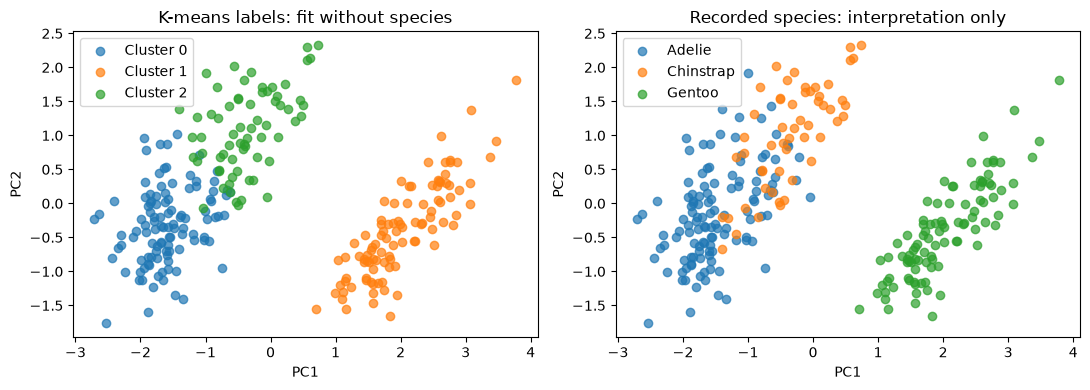

species,Adelie,Chinstrap,Gentoo
cluster,,,
0,103,5,0
1,0,0,98
2,18,49,0


In [8]:
y_train = training_view[TARGET].copy()  # Recorded labels enter interpretation only now.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for cluster in range(3):
    mask = clusters == cluster
    axes[0].scatter(projection[mask, 0], projection[mask, 1], label=f'Cluster {cluster}', alpha=.7)
for species in CLASS_ORDER:
    mask = y_train.eq(species).to_numpy()
    axes[1].scatter(projection[mask, 0], projection[mask, 1], label=species, alpha=.7)
for ax in axes:
    ax.set(xlabel='PC1', ylabel='PC2'); ax.legend()
axes[0].set_title('K-means labels: fit without species')
axes[1].set_title('Recorded species: interpretation only')
fig.tight_layout(); plt.show()
display(pd.crosstab(pd.Series(clusters, index=y_train.index, name='cluster'), y_train))


## 6. Interpretation and limits
Compare cluster means in original units and read the cross-table before naming groups. Separation in the projection need not imply separation in every input. Inertia and silhouette describe geometry, not biological truth or classification accuracy. No search over k, labels, inputs or PCA components was performed to maximise species agreement. This is a descriptive fit on complete development measurements; it does not establish transfer to new populations.

References: [PCA](https://scikit-learn.org/stable/modules/decomposition.html#pca), [K-means](https://scikit-learn.org/stable/modules/clustering.html#k-means). AI assisted drafting and code; the author must understand and review the work.

**Observed results:** two principal components retain 88.57% of scaled development variance. K-means yields groups of 108, 98 and 67 observations; the retained run converges in ten iterations and silhouette is 0.459. Read the original-unit profiles and species cross-table above rather than treating that number as prediction accuracy.